In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os
import glob

print("Current folder:")
print(os.getcwd())

print("\nCSV files found:")
print(glob.glob("**/*.csv", recursive=True))

Current folder:
C:\Users\dilee

CSV files found:
['employees_output.csv', 'employees_task2.csv', 'students.csv', 'students_1.csv', 'students_2.csv', 'student_analysis.csv', 'student_data.csv', 'titanic_cleaned.csv', 'titanic_feature_engineered.csv', 'titanic_predictions.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\data_x_x2_x3.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\msft.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\matplotlib\\mpl-data\\sample_data\\Stocks.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\mt19937-testset-1.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\mt19937-testset-2.csv', 'AppData\\Local\\Programs\\Python\\Python311\\Lib\\site-packages\\numpy\\random\\tests\\data\\pcg64-testset-1.csv', 'AppData\\Local\\Programs

In [5]:
import os
import glob

print("Current folder:", os.getcwd())

print("\nCSV files found:")
for file in glob.glob("**/*.csv", recursive=True):
    print(file)

Current folder: C:\Users\dilee

CSV files found:
employees_output.csv
employees_task2.csv
students.csv
students_1.csv
students_2.csv
student_analysis.csv
student_data.csv
titanic_cleaned.csv
titanic_feature_engineered.csv
titanic_predictions.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\random\tests\data\mt19937-testset-1.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\random\tests\data\mt19937-testset-2.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\random\tests\data\pcg64-testset-1.csv
AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\random\tests\data\pcg64-testset-2.csv
AppData\Local\Programs\Python\Pytho

In [6]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [7]:
numerical_df = df.select_dtypes(include="number")

correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.49
size,0.60,0.49,1.00


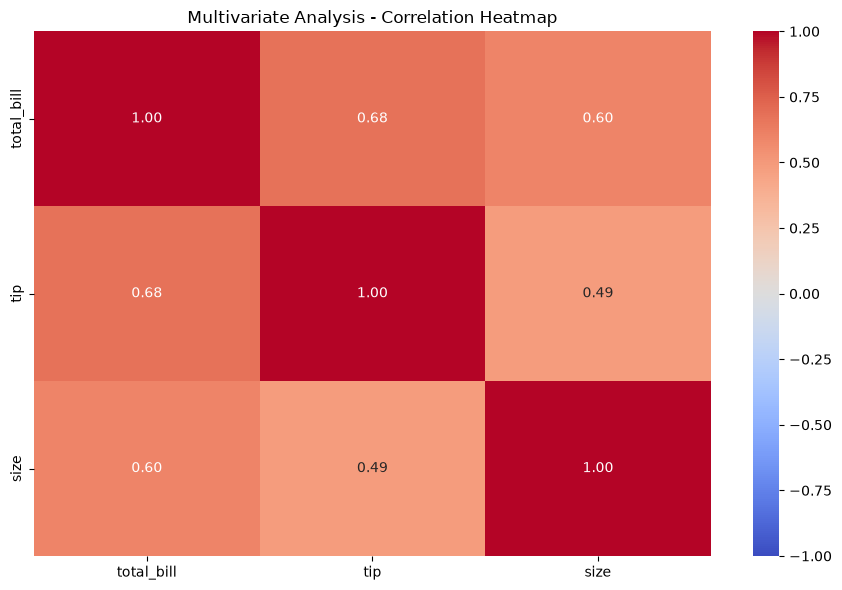

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_df = df.select_dtypes(include="number")
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Multivariate Analysis - Correlation Heatmap")
plt.tight_layout()
plt.show()

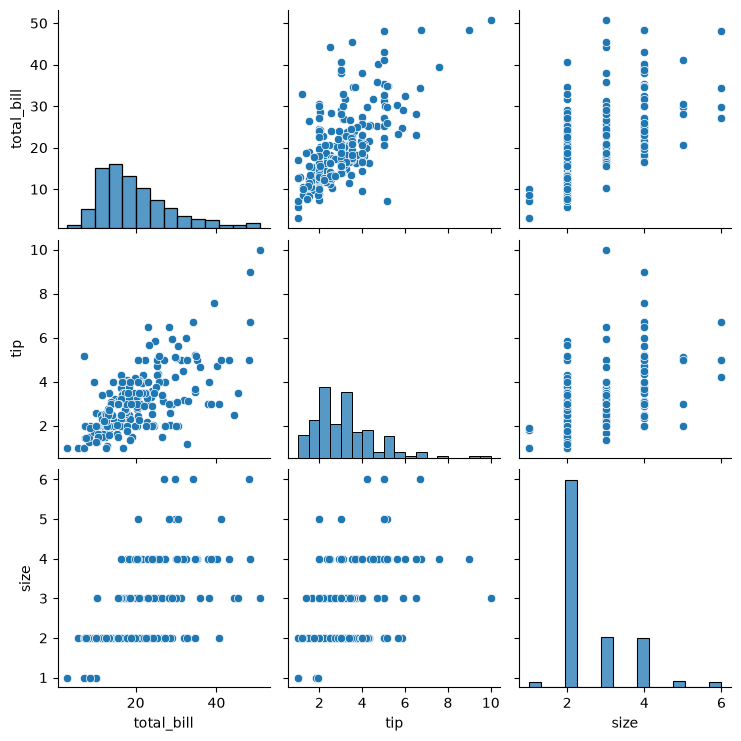

In [9]:
sns.pairplot(numerical_df)
plt.show()

In [10]:
# Calculate the correlation matrix
correlation_matrix = df.select_dtypes(include="number").corr()

# Get unique pairs of variables
correlation_pairs = correlation_matrix.unstack()

# Remove self-correlations and duplicate pairs
correlation_pairs = correlation_pairs[
    correlation_pairs.index.get_level_values(0)
    < correlation_pairs.index.get_level_values(1)
]

# Sort by absolute correlation
correlation_pairs = correlation_pairs.reindex(
    correlation_pairs.abs().sort_values(ascending=False).index
)

print("Strongest relationships between variables:")
display(correlation_pairs.head(10))

Strongest relationships between variables:


tip   total_bill    0.675734
size  total_bill    0.598315
      tip           0.489299
dtype: float64

In [11]:
threshold = 0.7

high_correlations = correlation_pairs[
    correlation_pairs.abs() >= threshold
]

print("Variable pairs with absolute correlation >= 0.7:")
display(high_correlations)

Variable pairs with absolute correlation >= 0.7:


Series([], dtype: float64)

In [12]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [13]:
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical variables and remove rows with missing values
numerical_df = df.select_dtypes(include="number").dropna()

# Remove constant columns
numerical_df = numerical_df.loc[
    :, numerical_df.nunique() > 1
]

# Calculate VIF
vif_data = pd.DataFrame()
vif_data["Feature"] = numerical_df.columns
vif_data["VIF"] = [
    variance_inflation_factor(numerical_df.values, i)
    for i in range(numerical_df.shape[1])
]

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
0,total_bill,13.165250
1,tip,10.232970
2,size,9.608373


In [14]:
print("MULTIVARIATE ANALYSIS SUMMARY")
print("-" * 40)

numerical_df = df.select_dtypes(include="number")

print("Dataset shape:", df.shape)
print("\nNumerical columns:")
print(list(numerical_df.columns))

print("\nMissing values in numerical columns:")
print(numerical_df.isnull().sum())

print("\nCorrelation matrix:")
display(numerical_df.corr().round(2))

MULTIVARIATE ANALYSIS SUMMARY
----------------------------------------
Dataset shape: (244, 7)

Numerical columns:
['total_bill', 'tip', 'size']

Missing values in numerical columns:
total_bill    0
tip           0
size          0
dtype: int64

Correlation matrix:


,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.49
size,0.60,0.49,1.00


## Conclusion

In this notebook, I performed multivariate analysis to understand relationships among multiple numerical variables. I used a correlation matrix and heatmap to identify relationships between variables, a pair plot to visualize patterns, and correlation analysis to identify strongly related variable pairs. I also calculated the Variance Inflation Factor (VIF) to investigate potential multicollinearity. These techniques help identify patterns and improve understanding of the dataset before further statistical analysis or machine learning.